<a href="https://www.kaggle.com/code/farzanaakteromi/diabetes-prediction-system-ipynb?scriptVersionId=374052573" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Diabetes Prediction System

## Project objective

The objective of this project is to build a machine learning pipeline that classifies the survey-derived diabetes indicator using health and lifestyle information.

- `Diabetes_binary = 0`: No diabetes
- `Diabetes_binary = 1`: Diabetes or prediabetes, as grouped in the source dataset

## Notebook roadmap

1. Setup and first look
2. Exploratory Data Analysis (EDA)
3. Train/test split and preprocessing
4. Model training
5. Classification evaluation
6. Prediction demonstration
7. Conclusion and responsible use

The notebook follows the project instructions. It uses the full binary dataset, preserves the original rows, keeps the test set untouched during model selection, and reports metrics beyond accuracy.

## 1. Setup and first look

### 1.1 Import libraries

Kaggle's standard Python environment already includes the libraries used in this notebook. Therefore, no `pip install` command is needed.

We use:
- **NumPy and Pandas** for data handling.
- **Matplotlib and Seaborn** for visualizations.
- **Scikit-learn** for splitting, preprocessing, model training, and evaluation.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/farzanaakteromi/dibates-dataset/diabetes_binary_health_indicators_BRFSS2015.csv


In [2]:
# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Import tools for data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
# Import evaluation metrics and visualization tools
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

### 1.2 Load the dataset

We load the required full binary dataset. The assignment asks us to use the 253,680-row binary file, not the smaller balanced subset and not the three-class dataset.

In [3]:
# Load the diabetes dataset
diabetes_data = pd.read_csv("/kaggle/input/datasets/farzanaakteromi/dibates-dataset/diabetes_binary_health_indicators_BRFSS2015.csv")
# Display the first five rows
diabetes_data.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### 1.4 Inspect the dataset

We first check the number of rows and columns, preview some records, inspect column names, and review data types. This gives us an initial understanding of the dataset.

In [4]:
# Display the number of rows and columns
print("Dataset shape:", diabetes_data.shape)
# Display the first five records
display(diabetes_data.head())
# Display all column names
print("\nColumn names:")
print(diabetes_data.columns.tolist())
# Display data types and non-null counts
print("\nDataset information:")
diabetes_data.info()

Dataset shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Column names:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64


### 1.5 Statistical summary and data quality checks

The source describes 21 predictor features and one target column. We verify missing values, duplicated rows, and statistical ranges before starting EDA.

In [5]:
# Show descriptive statistics
display(diabetes_data.describe().T)
# Count missing values in each column
print("Missing values by column:")
display(diabetes_data.isnull().sum().to_frame("Missing Values"))
#Count all missing values
print("Total missing values:", diabetes_data.isnull().sum().sum())
# Count duplicated rows without deleting them
duplicate_count = diabetes_data.duplicated().sum()
print("Duplicate rows:", duplicate_count)
# Check data types
print("\nData types:")
display(diabetes_data.dtypes.to_frame("Data Type"))

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


Missing values by column:


,Missing Values
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0


Total missing values: 0
Duplicate rows: 24206

Data types:


,Data Type
Diabetes_binary,float64
HighBP,float64
HighChol,float64
CholCheck,float64
BMI,float64
Smoker,float64
Stroke,float64
HeartDiseaseorAttack,float64
PhysActivity,float64
Fruits,float64


### 1.6 Check target distribution

The target column is `Diabetes_binary`. We calculate the number and percentage of records in each class. This is important because the positive class is smaller than the negative class, so accuracy alone may give an incomplete picture of model performance.

In [6]:
# Count records in each target class
diabetes_counts = diabetes_data["Diabetes_binary"].value_counts().sort_index()
# Calculate the percentage of each target class
diabetes_percentages = (diabetes_data["Diabetes_binary"].value_counts(normalize=True).sort_index() * 100)
# Create a readable target summary
target_summary = pd.DataFrame({
    "Count": diabetes_counts,
    "Percentage": diabetes_percentages
})
target_summary.index = ["No diabetes (0)", "Diabetes/prediabetes (1)"]

display(target_summary)

# Calculate positive-class prevalence
positive_prevalence = (diabetes_data["Diabetes_binary"] == 1).mean()
print(f"Positive-class prevalence: {positive_prevalence:.2%}")

,Count,Percentage
No diabetes (0),218334,86.066698
Diabetes/prediabetes (1),35346,13.933302


Positive-class prevalence: 13.93%


### 1.7 Check expected columns and value ranges

The project requires 21 predictors and one target. We verify the column count and inspect the unique values of selected binary and ordinal variables. This helps identify unexpected values before modeling.

In [7]:
# Check the target column
target_column = "Diabetes_binary"
if target_column not in diabetes_data.columns:
    raise ValueError("The target column Diabetes_binary is missing.")
# Separate predictor names from the target
feature_names = [column for column in diabetes_data.columns if column != target_column]
print("Number of predictors:", len(feature_names))
print("Number of target columns:", 1)
# Check binary and ordinal variables
binary_columns = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]
ordinal_columns = ["GenHlth", "Age", "Education", "Income"]
numeric_columns = ["BMI", "MentHlth", "PhysHlth"]
print("\nUnique values in binary columns:")
for column in binary_columns:
    print(column, sorted(diabetes_data[column].dropna().unique().tolist()))
print("\nUnique values in ordinal columns:")
for column in ordinal_columns:
    print(column, sorted(diabetes_data[column].dropna().unique().tolist()))
print("\nNumeric feature ranges:")
display(diabetes_data[numeric_columns].agg(["min", "max"]).T)

Number of predictors: 21
Number of target columns: 1

Unique values in binary columns:
HighBP [0.0, 1.0]
HighChol [0.0, 1.0]
CholCheck [0.0, 1.0]
Smoker [0.0, 1.0]
Stroke [0.0, 1.0]
HeartDiseaseorAttack [0.0, 1.0]
PhysActivity [0.0, 1.0]
Fruits [0.0, 1.0]
Veggies [0.0, 1.0]
HvyAlcoholConsump [0.0, 1.0]
AnyHealthcare [0.0, 1.0]
NoDocbcCost [0.0, 1.0]
DiffWalk [0.0, 1.0]
Sex [0.0, 1.0]

Unique values in ordinal columns:
GenHlth [1.0, 2.0, 3.0, 4.0, 5.0]
Age [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0]
Education [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
Income [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]

Numeric feature ranges:


,min,max
BMI,12.0,98.0
MentHlth,0.0,30.0
PhysHlth,0.0,30.0


## 2. Exploratory Data Analysis (EDA)

EDA helps us understand patterns and relationships in the survey data before training machine learning models. We will create at least five plots.
When comparing diabetes rates across groups, we use the **percentage of positive records within each group**, rather than raw counts. This is more appropriate when group sizes are different.
These plots show associations in the survey data. They do not prove that one feature causes diabetes.

### 2.1 Plot 1 — Target distribution

This bar chart displays the number of records in each target class. It helps us see the class imbalance.

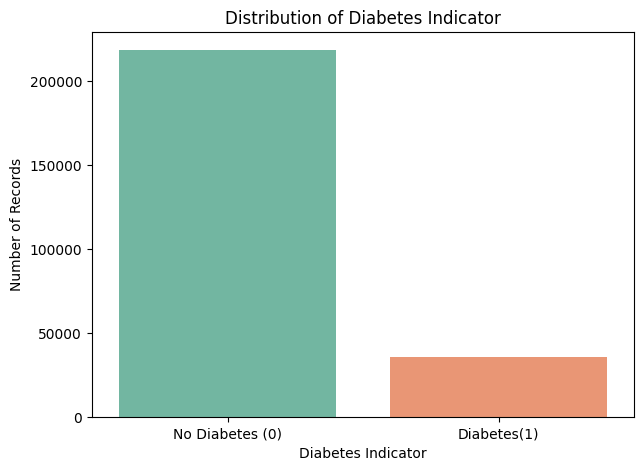

In [8]:
# Plot target distribution
plt.figure(figsize=(7, 5))
sns.countplot(
    data=diabetes_data,
    x="Diabetes_binary",
    hue="Diabetes_binary",
    palette="Set2",
    legend=False
)
plt.title("Distribution of Diabetes Indicator")
plt.xlabel("Diabetes Indicator")
plt.ylabel("Number of Records")
plt.xticks(
    [0, 1],
    ["No Diabetes (0)", "Diabetes(1)"]
)
plt.show()

### 2.2 Plot 2 — BMI distribution

BMI is a numeric feature. A histogram helps us understand its distribution and identify where most survey records are concentrated.

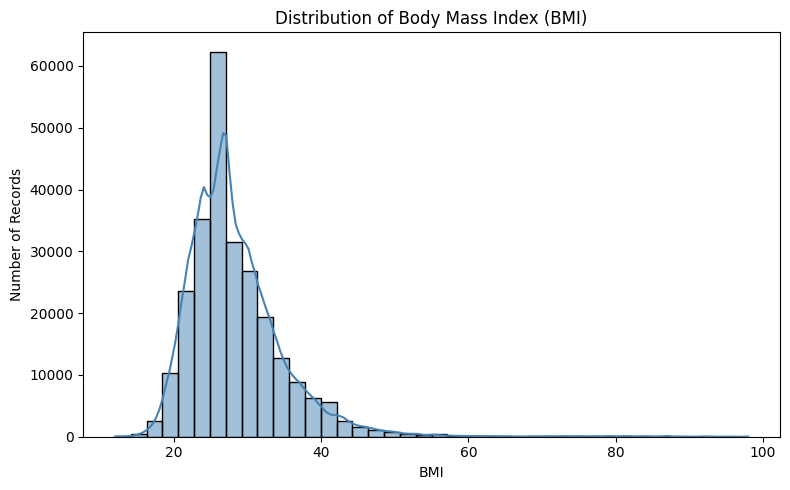

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=diabetes_data,
    x="BMI",
    bins=40,
    kde=True,
    color="steelblue"
)
plt.title("Distribution of Body Mass Index (BMI)")
plt.xlabel("BMI")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### 2.3 Plot 3 — Diabetes rate across age groups

The `Age` column contains 13 ordered age categories, not exact ages. We calculate the percentage of positive target records within each age category.

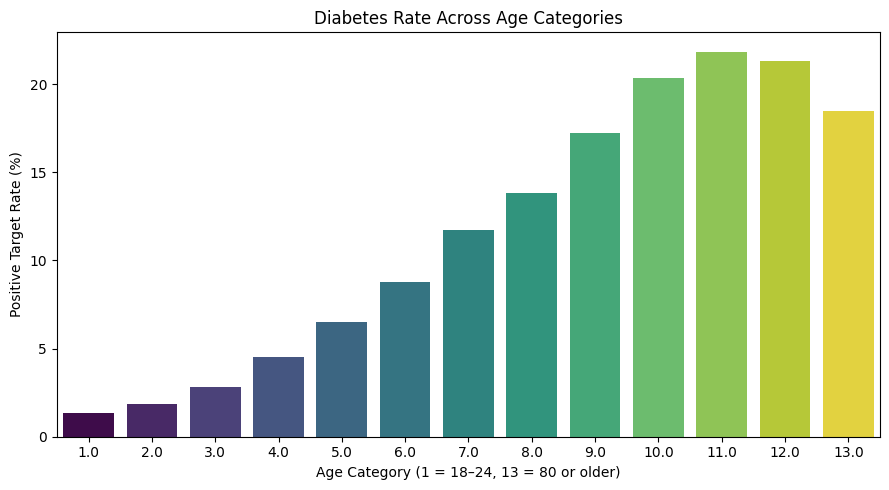

,Age,Diabetes Rate (%)
0,1.0,1.368421
1,2.0,1.842590
2,3.0,2.822979
3,4.0,4.528684
4,5.0,6.504920
5,6.0,8.789545
6,7.0,11.735198
7,8.0,13.826544
8,9.0,17.245217
9,10.0,20.370255


In [10]:
age_diabetes_rate = (
    diabetes_data.groupby("Age")["Diabetes_binary"].mean() * 100
).reset_index(name="Diabetes Rate (%)")

plt.figure(figsize=(9, 5))
sns.barplot(
    data=age_diabetes_rate,
    x="Age",
    y="Diabetes Rate (%)",
    hue="Age",
    palette="viridis",
    legend=False
)

plt.title("Diabetes Rate Across Age Categories")
plt.xlabel("Age Category (1 = 18–24, 13 = 80 or older)")
plt.ylabel("Positive Target Rate (%)")
plt.tight_layout()
plt.show()

display(age_diabetes_rate)

### 2.4 Plot 4 — Diabetes rate by general health

`GenHlth` is an ordinal feature: 1 means excellent general health and 5 means poor general health. We compare the positive target rate across these categories.

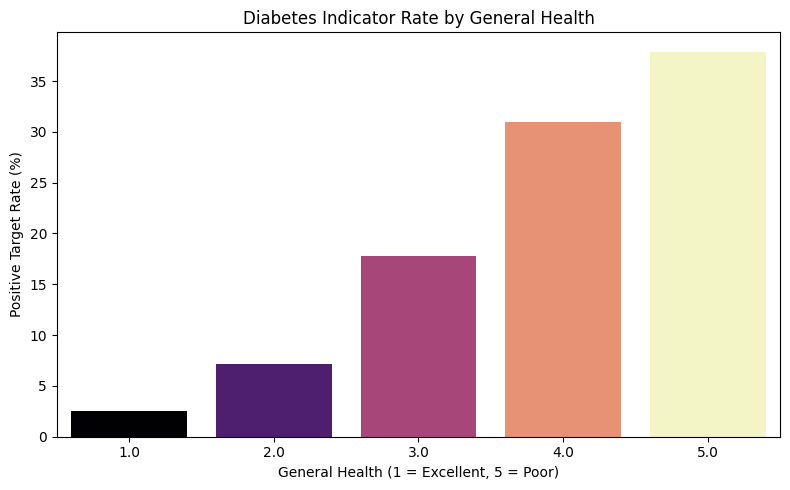

,GenHlth,Diabetes Rate (%)
0,1.0,2.516612
1,2.0,7.162902
2,3.0,17.789440
3,4.0,31.010453
4,5.0,37.894214


In [11]:
health_diabetes_rate = (
    diabetes_data.groupby("GenHlth")["Diabetes_binary"].mean() * 100
).reset_index(name="Diabetes Rate (%)")
plt.figure(figsize=(8, 5))
sns.barplot(
    data=health_diabetes_rate,
    x="GenHlth",
    y="Diabetes Rate (%)",
    hue="GenHlth",
    palette="magma",
    legend=False
)
plt.title("Diabetes Indicator Rate by General Health")
plt.xlabel("General Health (1 = Excellent, 5 = Poor)")
plt.ylabel("Positive Target Rate (%)")
plt.tight_layout()
plt.show()
display(health_diabetes_rate)

### 2.5 Plot 5 — BMI by target class

A boxplot compares the BMI distributions of the two target groups. The median and spread can be compared, while points outside the whiskers may indicate unusually high or low values.

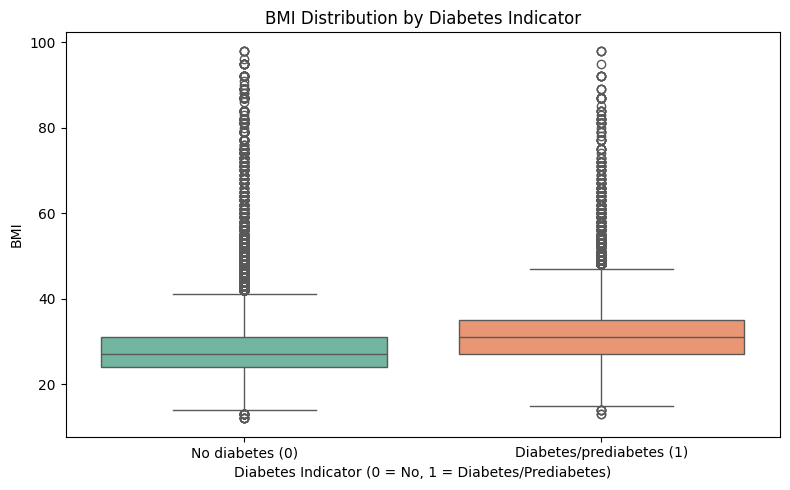

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=diabetes_data,
    x="Diabetes_binary",
    y="BMI",
    hue="Diabetes_binary",
    palette="Set2",
    legend=False
)
plt.title("BMI Distribution by Diabetes Indicator")
plt.xlabel("Diabetes Indicator (0 = No, 1 = Diabetes/Prediabetes)")
plt.ylabel("BMI")
plt.xticks([0, 1], ["No diabetes (0)", "Diabetes/prediabetes (1)"])
plt.tight_layout()
plt.show()

### 2.6 Optional supporting plot — High blood pressure

This plot compares the positive target rate among respondents with and without high blood pressure. It is an additional descriptive analysis, not evidence of causation.

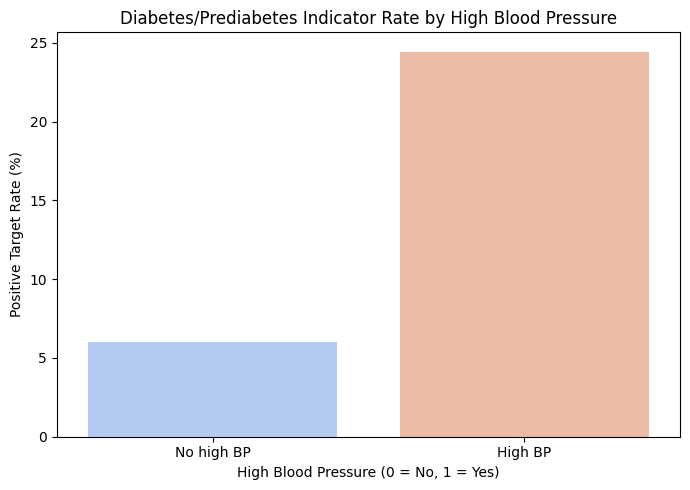

,HighBP,Diabetes Rate (%)
0,0.0,6.035167
1,1.0,24.445690


In [13]:
blood_pressure_rate = (
    diabetes_data.groupby("HighBP")["Diabetes_binary"].mean() * 100
).reset_index(name="Diabetes Rate (%)")

plt.figure(figsize=(7, 5))
sns.barplot(
    data=blood_pressure_rate,
    x="HighBP",
    y="Diabetes Rate (%)",
    hue="HighBP",
    palette="coolwarm",
    legend=False
)

plt.title("Diabetes/Prediabetes Indicator Rate by High Blood Pressure")
plt.xlabel("High Blood Pressure (0 = No, 1 = Yes)")
plt.ylabel("Positive Target Rate (%)")
plt.xticks([0, 1], ["No high BP", "High BP"])
plt.tight_layout()
plt.show()

display(blood_pressure_rate)

### 2.7 EDA Findings

Based on the exploratory data analysis, the following observations were identified:

1. **Class Distribution:** The dataset is imbalanced, with approximately 86.07% of records belonging to the No Diabetes class (0) and 13.93% belonging to the Diabetes/Prediabetes class (1). This indicates that the negative class significantly outnumbers the positive class.

2. **BMI Distribution:** The BMI distribution is right-skewed, with most records concentrated between approximately 20 and 35. A smaller number of observations have considerably higher BMI values, creating a long right tail and several potential outliers.

3. **Age Groups:** The diabetes rate generally increases across age categories. It rises from approximately 1.37% in the first age category to a peak of 21.85% in age category 11 (coded value 11), before decreasing slightly in the following categories. This suggests an association between age category and the diabetes indicator.

4. **General Health (GenHlth):** The diabetes rate increases consistently across the GenHlth categories, from 2.52% in category 1 to 37.89% in category 5. This indicates that respondents reporting poorer general health have a higher observed diabetes rate.

5. **BMI by Diabetes Indicator:** The boxplot shows that the median BMI is higher among respondents with diabetes/prediabetes than among those without the indicator. The positive class also shows a slightly wider BMI distribution. Both groups contain several high-BMI outliers.

6. **High Blood Pressure (HighBP):** The observed diabetes rate is approximately 6.04% among respondents without high blood pressure (HighBP = 0), compared with 24.45% among respondents with high blood pressure (HighBP = 1). This represents a substantial difference between the two groups.

**Overall Observation:** The EDA suggests that BMI, age category, general health status, and high blood pressure are associated with differences in the observed diabetes indicator rates. However, these findings represent associations in historical self-reported survey data and do not establish causal relationships.

## 3. Train/Test Split and Preprocessing

### 3.1 Separate predictors and target

We separate the 21 predictor columns from `Diabetes_binary`. The target must never be included in the predictor matrix because that would cause data leakage.

In [14]:
# Separate input features and target
X = diabetes_data.drop(columns=["Diabetes_binary"])
y = diabetes_data["Diabetes_binary"].astype(int)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique().tolist()))

Feature shape: (253680, 21)
Target shape: (253680,)
Target values: [0, 1]


### 3.2 Split the data

We reserve 20% of the data for final testing and use 80% for training.

- `test_size=0.20`: 20% of records are held out for testing.
- `stratify=y`: preserves approximately the same target class proportions in both sets.
- `random_state=42`: makes the split reproducible.

The test set will not be used for hyperparameter selection or model selection.

In [15]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index().mul(100).to_frame("Percentage"))
print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).to_frame("Percentage"))

Training feature shape: (202944, 21)
Testing feature shape: (50736, 21)

Training target distribution:


,Percentage
Diabetes_binary,
0,86.0666
1,13.9334



Testing target distribution:


,Percentage
Diabetes_binary,
0,86.067092
1,13.932908


### 3.3 Choose feature groups

The dataset contains different types of variables:

- **Binary:** yes/no indicators and the `Sex` indicator.
- **Ordinal:** `GenHlth`, `Age`, `Education`, and `Income`, whose values have an ordered meaning.
- **Numeric:** `BMI`, `MentHlth`, and `PhysHlth`.

We keep binary and ordinal values in their existing numeric representation. We standardize the three numeric features because scaling can help scale-sensitive models such as Logistic Regression and Linear SVM.

The preprocessing steps are placed inside a Scikit-learn pipeline. This means the imputer and scaler are fitted on training data only, helping prevent data leakage. The same fitted transformations are then applied to the test data and prediction examples.

In [16]:
# Define the numeric and remaining feature columns
numeric_features = ["BMI", "MentHlth", "PhysHlth"]
other_features = [column for column in X.columns if column not in numeric_features]

# Preprocess numeric features: fill missing values and standardize
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
# Preprocess binary and ordinal features: fill missing values
other_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])
# Combine the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("other", other_transformer, other_features)
    ],
    remainder="drop"
)
print("Preprocessing pipeline created successfully.")
print("Numeric features:", numeric_features)
print("Binary and ordinal features:", other_features)

Preprocessing pipeline created successfully.
Numeric features: ['BMI', 'MentHlth', 'PhysHlth']
Binary and ordinal features: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


## 4. Model Training

We train three classification models:

1. **Logistic Regression:** A linear classification model that estimates class probabilities.
2. **Linear Support Vector Machine (Linear SVM):** Finds a decision boundary that separates the classes. We use `LinearSVC` because it is more practical than a kernel SVM for this large dataset.
3. **Random Forest:** Combines multiple decision trees and can model nonlinear relationships.

Each model is placed in a pipeline with the same preprocessing steps. We use class weighting to account for the imbalanced target classes. These settings are reproducible and are not selected using the final test set.

Training may take some time because the dataset contains more than 250,000 records.

In [17]:
# Create the Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Create the Linear SVM pipeline
svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Create the Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])
# Store models in a dictionary
models = {
    "Logistic Regression": logistic_model,
    "Linear SVM": svm_model,
    "Random Forest": random_forest_model
}
print("Three machine learning models are ready.")

Three machine learning models are ready.


### 4.1 Train the models

We fit each model using only the training data. The preprocessing steps are also fitted during this process.

In [18]:
# Train each model
for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    print(f"{model_name} training completed.\n")

print("All models have been trained.")

Training Logistic Regression...
Logistic Regression training completed.

Training Linear SVM...
Linear SVM training completed.

Training Random Forest...
Random Forest training completed.

All models have been trained.


## 5. Classification Evaluation

### 5.1 Evaluate the models on the test set

We use the untouched test set for final evaluation.

The metrics are:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision (class 1):** Of the records predicted as positive, how many are actually positive?
- **Recall (class 1):** Of all actual positive records, how many did the model identify?
- **F1-score (class 1):** Harmonic mean of positive-class precision and recall.
- **ROC-AUC:** Measures ranking performance across classification thresholds.
- **PR-AUC / Average Precision:** Summarizes the precision-recall curve and is useful when the positive class is less common.

For Linear SVM, we use its decision scores for ROC-AUC and average precision because `LinearSVC` does not provide `predict_proba()`.

In [19]:
# Create dictionaries to store evaluation results
model_results = []
model_predictions = {}
model_scores = {}
for model_name, model in models.items():
    y_pred = model.predict(X_test)
    model_predictions[model_name] = y_pred
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    model_scores[model_name] = y_score
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Class 1)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (Class 1)": recall_score(y_test, y_pred, zero_division=0),
        "F1-score (Class 1)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "PR-AUC (Average Precision)": average_precision_score(y_test, y_score)
    })
# Create and display the model comparison table
model_comparison = pd.DataFrame(model_results)
model_comparison = model_comparison.sort_values(
    by="F1-score (Class 1)",
    ascending=False
).reset_index(drop=True)
display(model_comparison.round(4))

,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1),ROC-AUC,PR-AUC (Average Precision)
0,Logistic Regression,0.7316,0.3108,0.7612,0.4414,0.8196,0.3926
1,Linear SVM,0.7275,0.3083,0.7686,0.4400,0.8194,0.3936
2,Random Forest,0.8361,0.4120,0.4134,0.4127,0.8123,0.3998


### 5.2 Majority-class baseline

A simple majority-class baseline always predicts the most common class in the training data. Since the positive class is less common, this baseline can achieve a seemingly high accuracy while failing to identify positive records.

We compare the models with this baseline to understand why accuracy alone is not enough.

In [20]:
# Predict the majority class for every test record
majority_class = y_train.value_counts().idxmax()
baseline_predictions = np.full(shape=len(y_test), fill_value=majority_class)
baseline_results = {
    "Majority class": majority_class,
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision (Class 1)": precision_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "Recall (Class 1)": recall_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "F1-score (Class 1)": f1_score(
        y_test, baseline_predictions, zero_division=0
    )
}
display(pd.DataFrame([baseline_results]).round(4))

,Majority class,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1)
0,0,0.8607,0.0,0.0,0.0


## Result Analysis

The majority-class baseline achieved **86.07% accuracy** by predicting every instance as the negative class. However, its precision, recall, and F1-score for the positive class were all **zero**.

This demonstrates that accuracy alone is insufficient for evaluating models on this imbalanced dataset.

**Logistic Regression** and **Linear SVM** achieved substantially higher positive-class recall, indicating their ability to identify diabetes-related positive cases that the baseline completely missed.

### 5.3 Confusion matrices

A confusion matrix shows four types of outcomes:

- **True Negative (TN):** Actual class 0 correctly predicted as 0.
- **False Positive (FP):** Actual class 0 incorrectly predicted as 1.
- **False Negative (FN):** Actual class 1 incorrectly predicted as 0.
- **True Positive (TP):** Actual class 1 correctly predicted as 1.

A false negative means that a positive survey indicator was missed by the model. A false positive means that a negative survey indicator was predicted as positive. Neither output should be interpreted as a clinical diagnosis.

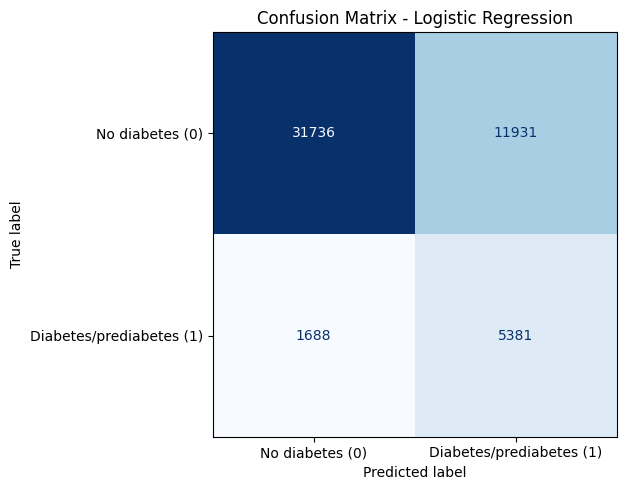

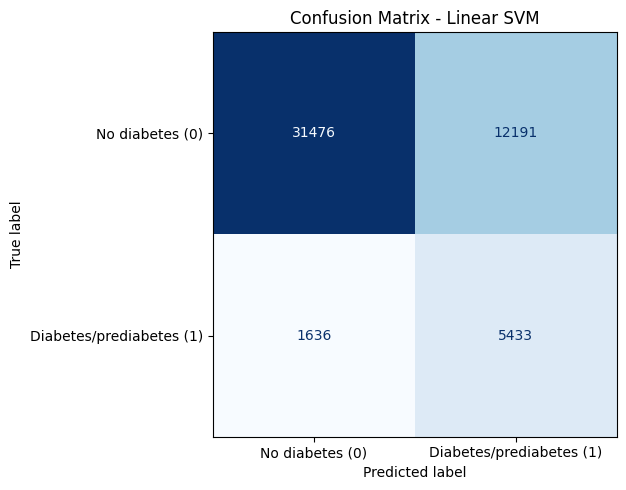

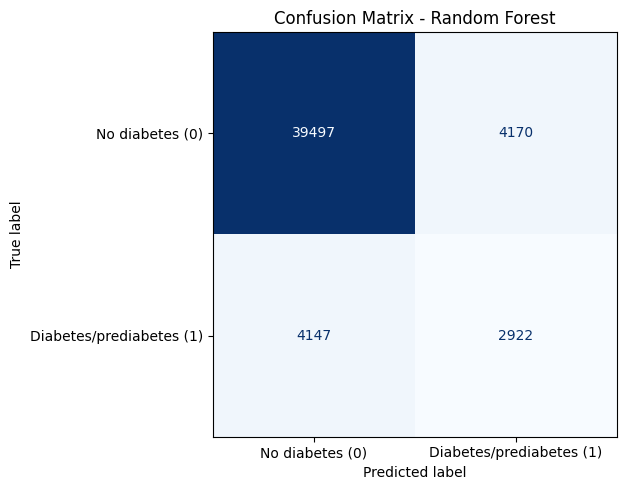

In [21]:
# Draw a confusion matrix for each model
for model_name, y_pred in model_predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No diabetes (0)", "Diabetes/prediabetes (1)"]
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )
    ax.set_title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

### 5.4 Classification reports

The classification report provides precision, recall, F1-score, and support for both classes. We pay particular attention to class 1 because it is the positive target class.

In [22]:
# Display the classification report for each model
for model_name, y_pred in model_predictions.items():
    print("=" * 65)
    print(model_name)
    print("=" * 65)
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No diabetes (0)", "Diabetes/prediabetes (1)"],
            zero_division=0
        )
    )

Logistic Regression
                          precision    recall  f1-score   support

         No diabetes (0)       0.95      0.73      0.82     43667
Diabetes/prediabetes (1)       0.31      0.76      0.44      7069

                accuracy                           0.73     50736
               macro avg       0.63      0.74      0.63     50736
            weighted avg       0.86      0.73      0.77     50736

Linear SVM
                          precision    recall  f1-score   support

         No diabetes (0)       0.95      0.72      0.82     43667
Diabetes/prediabetes (1)       0.31      0.77      0.44      7069

                accuracy                           0.73     50736
               macro avg       0.63      0.74      0.63     50736
            weighted avg       0.86      0.73      0.77     50736

Random Forest
                          precision    recall  f1-score   support

         No diabetes (0)       0.90      0.90      0.90     43667
Diabetes/prediabetes (1)

## Classification Report Analysis

### Logistic Regression
Logistic Regression achieved a recall of 0.76 and an F1-score of 0.44 for the positive class (Diabetes/Prediabetes). This indicates that the model successfully identified approximately 76% of actual positive cases. However, its precision was relatively low at 0.31.

### Linear SVM
Linear SVM achieved the highest positive-class recall of 0.77, with a precision of 0.31 and an F1-score of 0.44. Its performance was very similar to Logistic Regression, with slightly better recall.

### Random Forest
Random Forest achieved the highest accuracy of 0.84 and the highest positive-class precision of 0.41. However, its recall was only 0.41, meaning it failed to identify a considerable proportion of actual positive cases.

### Overall Observation
Logistic Regression and Linear SVM performed better in identifying positive cases, while Random Forest achieved higher overall accuracy. Since the dataset is imbalanced, accuracy alone is not sufficient for model comparison. Positive-class recall, precision, and F1-score should also be considered.

### 5.5 ROC curves

The ROC curve shows the relationship between the true positive rate and false positive rate at different score thresholds. We plot all three models to compare their ranking performance.

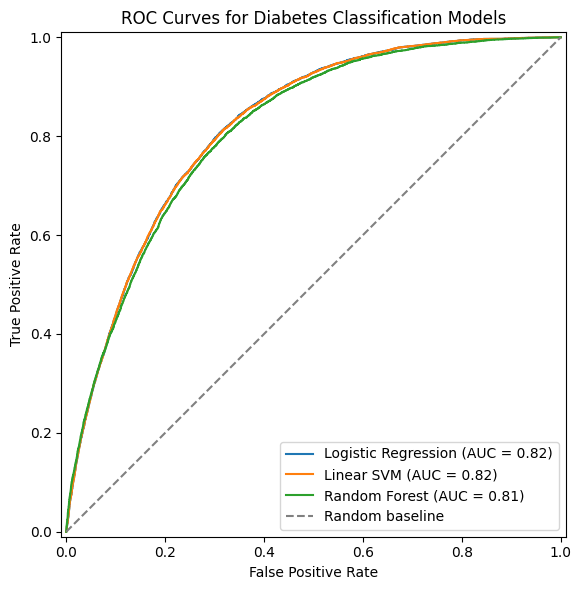

In [23]:
plt.figure(figsize=(8, 6))
for model_name, y_score in model_scores.items():
    RocCurveDisplay.from_predictions(
        y_test,
        y_score,
        name=model_name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
plt.title("ROC Curves for Diabetes Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

## ROC Curve Analysis

The ROC curves illustrate the classification performance of the three machine learning models at different classification thresholds.

- **Logistic Regression** achieved an ROC-AUC of 0.82, indicating good discrimination between the two classes.
- **Linear SVM** also achieved an ROC-AUC of 0.82, showing performance similar to Logistic Regression.
- **Random Forest** achieved an ROC-AUC of 0.81, which is slightly lower than the other two models.

All three ROC curves remain above the random baseline (AUC = 0.50), indicating that the models perform better than random classification.

Overall, Logistic Regression and Linear SVM demonstrated slightly better ROC-AUC performance than Random Forest. However, the differences are small.

### 5.6 Precision-Recall curves

The Precision-Recall curve shows the trade-off between precision and recall at different thresholds. It is especially useful to inspect when the positive class is less common.

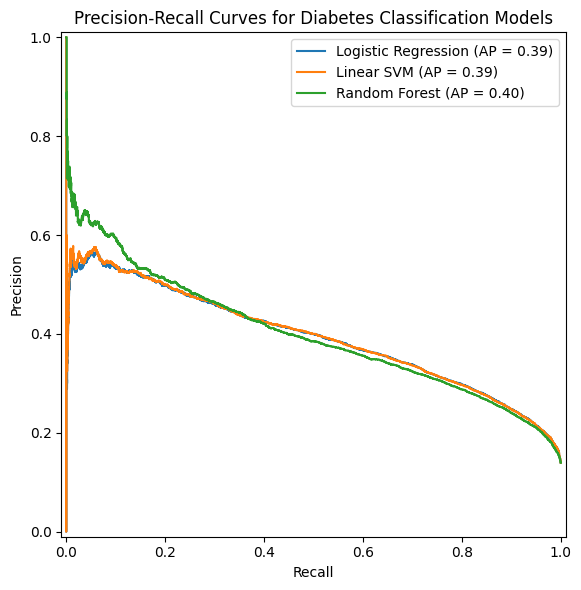

In [24]:
plt.figure(figsize=(8, 6))
for model_name, y_score in model_scores.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_score,
        name=model_name,
        ax=plt.gca()
    )
plt.title("Precision-Recall Curves for Diabetes Classification Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

## Precision-Recall Curve Analysis

The Precision-Recall (PR) curves illustrate the trade-off between precision and recall for the three classification models at different classification thresholds.

- **Logistic Regression** achieved an Average Precision (AP) of approximately 0.39.
- **Linear SVM** also achieved an AP of approximately 0.39.
- **Random Forest** achieved the highest AP of approximately 0.40.

The three models demonstrated relatively similar Precision-Recall performance. Random Forest showed a slightly higher Average Precision than the other two models.

As recall increases, precision generally decreases, indicating a trade-off between identifying more positive cases and reducing false positive predictions.

Overall, Random Forest achieved the highest AP, while Logistic Regression and Linear SVM demonstrated higher positive-class recall at the evaluated classification threshold.

### 5.7 Select a model for the demonstration

For this educational demonstration, we select the model with the highest positive-class F1-score from the test comparison table. This is a simple comparison rule, not a claim that the selected model is clinically suitable.

The test set is used here for the assignment's final model comparison. We do not perform further tuning or threshold selection using it.

In [25]:
# Select the model with the highest positive-class F1-score
best_model_name = model_comparison.loc[0, "Model"]
best_model = models[best_model_name]
print("Selected model:", best_model_name)
print("\nSelected model's test metrics:")
display(
    model_comparison.loc[
        model_comparison["Model"] == best_model_name
    ].round(4)
)

Selected model: Logistic Regression

Selected model's test metrics:


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-score (Class 1),ROC-AUC,PR-AUC (Average Precision)
0,Logistic Regression,0.7316,0.3108,0.7612,0.4414,0.8196,0.3926


### 5.8 Discuss Model Errors and Trade-offs

Based on the model evaluation results, the following observations were identified:

1. **Highest Positive-Class Recall:** Linear SVM achieved the highest positive-class recall of 0.7686 (76.86%), followed closely by Logistic Regression at 0.7612 (76.12%). This indicates that Linear SVM identified the largest proportion of actual positive cases.

2. **Highest Positive-Class Precision:** Random Forest achieved the highest positive-class precision of approximately 0.4120 (41.20%). This means that among its positive predictions, a larger proportion were actually positive compared with the other models.

3. **Highest Positive-Class F1-score:** Logistic Regression achieved the highest positive-class F1-score of 0.4414, slightly outperforming Linear SVM (0.4400) and Random Forest (0.4127).

4. **Strongest ROC-AUC and PR-AUC:** Logistic Regression achieved the highest ROC-AUC of 0.8196, indicating slightly better overall discrimination between the two classes. However, Random Forest achieved the highest PR-AUC (Average Precision) of 0.3998, compared with Linear SVM (0.3936) and Logistic Regression (0.3926).

5. **Precision-Recall Trade-off:** Linear SVM and Logistic Regression achieved higher recall, meaning they identified more actual positive cases. However, their relatively low precision indicates that they also produced more false positive predictions. Random Forest achieved higher precision but lower recall, meaning it produced fewer false positives proportionally while missing more actual positive cases. Therefore, there is a trade-off between identifying more positive cases and reducing false alarms.

6. **Comparison with Majority-Class Baseline:** The majority-class baseline achieved 86.07% accuracy by predicting every instance as the negative class. However, its positive-class precision, recall, and F1-score were all zero. Although all three machine learning models achieved lower accuracy than the baseline, they successfully identified positive cases. Logistic Regression and Linear SVM showed substantially higher positive-class recall, while Random Forest provided a better balance in precision and recall than the baseline.

**Overall Conclusion:** Logistic Regression achieved the highest positive-class F1-score and ROC-AUC, while Linear SVM achieved the highest recall and Random Forest achieved the highest precision and PR-AUC. Therefore, model selection should consider the project's evaluation objectives rather than accuracy alone.

## 6. Prediction Demonstration

We now create a simple function that accepts all 21 predictor values and applies the same fitted preprocessing and classifier used during training.

The function:
- Checks that all required features are provided.
- Checks that the values are within the expected ranges.
- Uses the selected model pipeline for prediction.
- Displays the predicted class.
- Displays a probability when the selected model supports probability prediction.

The examples below are hypothetical and are not real patient records.

In [26]:
# Define valid ranges for the dataset features
valid_ranges = {
    "HighBP": (0, 1),
    "HighChol": (0, 1),
    "CholCheck": (0, 1),
    "BMI": (12, 98),
    "Smoker": (0, 1),
    "Stroke": (0, 1),
    "HeartDiseaseorAttack": (0, 1),
    "PhysActivity": (0, 1),
    "Fruits": (0, 1),
    "Veggies": (0, 1),
    "HvyAlcoholConsump": (0, 1),
    "AnyHealthcare": (0, 1),
    "NoDocbcCost": (0, 1),
    "GenHlth": (1, 5),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "DiffWalk": (0, 1),
    "Sex": (0, 1),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8)
}
# Define binary and ordinal columns that should contain integer values
integer_columns = binary_columns + ordinal_columns + ["MentHlth", "PhysHlth"]
def predict_diabetes_indicator(input_values):
    '''
    Predict the survey-derived diabetes indicator for one hypothetical record.
    This function is for educational demonstration only.
    '''
    # Check whether all required features are provided
    missing_features = [column for column in feature_names if column not in input_values]
    extra_features = [column for column in input_values if column not in feature_names]

    if missing_features:
        raise ValueError(f"Missing features: {missing_features}")

    if extra_features:
        raise ValueError(f"Unexpected features: {extra_features}")

    # Arrange values in the same order as the training features
    input_data = pd.DataFrame([input_values], columns=feature_names)

    # Check numeric values and allowed ranges
    for column, (minimum, maximum) in valid_ranges.items():

        value = input_data.loc[0, column]

        if pd.isna(value) or not np.isfinite(value):
            raise ValueError(f"{column} must contain a valid numeric value.")

        if value < minimum or value > maximum:
            raise ValueError(
                f"{column} must be between {minimum} and {maximum}."
            )

        if column in integer_columns and not float(value).is_integer():
            raise ValueError(f"{column} must be an integer value.")

    # Predict using the complete fitted pipeline
    predicted_class = int(best_model.predict(input_data)[0])

    print("Selected model:", best_model_name)

    if predicted_class == 1:
        print("Predicted class: 1 (Diabetes/prediabetes survey indicator)")
    else:
        print("Predicted class: 0 (No diabetes survey indicator)")

    # Display probability if the model supports predict_proba
    if hasattr(best_model, "predict_proba"):
        predicted_probability = best_model.predict_proba(input_data)[0][1]
        print(f"Estimated model probability for class 1: {predicted_probability:.2%}")
    else:
        print("Probability is not available for this selected model.")

    print("\nDisclaimer: This is an educational model output, not a medical diagnosis.")

### 6.1 Hypothetical example 1

This is a hypothetical survey profile with selected health and lifestyle indicators. The values are provided only to demonstrate how the prediction function works.

In [27]:
# Create the first hypothetical input record
example_one = {
    "HighBP": 1,
    "HighChol": 1,
    "CholCheck": 1,
    "BMI": 32,
    "Smoker": 0,
    "Stroke": 0,
    "HeartDiseaseorAttack": 0,
    "PhysActivity": 0,
    "Fruits": 1,
    "Veggies": 1,
    "HvyAlcoholConsump": 0,
    "AnyHealthcare": 1,
    "NoDocbcCost": 0,
    "GenHlth": 3,
    "MentHlth": 5,
    "PhysHlth": 10,
    "DiffWalk": 0,
    "Sex": 0,
    "Age": 8,
    "Education": 5,
    "Income": 5
}

predict_diabetes_indicator(example_one)

Selected model: Logistic Regression
Predicted class: 1 (Diabetes/prediabetes survey indicator)
Estimated model probability for class 1: 64.10%

Disclaimer: This is an educational model output, not a medical diagnosis.


### 6.2 Hypothetical example 2

This second hypothetical profile uses a different combination of health and lifestyle indicators. It demonstrates that the same prediction pipeline can process another record.

In [28]:
# Create the second hypothetical input record
example_two = {
    "HighBP": 0,
    "HighChol": 0,
    "CholCheck": 1,
    "BMI": 23,
    "Smoker": 0,
    "Stroke": 0,
    "HeartDiseaseorAttack": 0,
    "PhysActivity": 1,
    "Fruits": 1,
    "Veggies": 1,
    "HvyAlcoholConsump": 0,
    "AnyHealthcare": 1,
    "NoDocbcCost": 0,
    "GenHlth": 2,
    "MentHlth": 0,
    "PhysHlth": 0,
    "DiffWalk": 0,
    "Sex": 1,
    "Age": 3,
    "Education": 6,
    "Income": 8
}

predict_diabetes_indicator(example_two)

Selected model: Logistic Regression
Predicted class: 0 (No diabetes survey indicator)
Estimated model probability for class 1: 6.78%

Disclaimer: This is an educational model output, not a medical diagnosis.


## 7. Conclusion and Responsible Use

### 7.1 Project Conclusion

This project developed a machine learning classification pipeline using the CDC Diabetes Health Indicators dataset from BRFSS 2015. Three classification algorithms—Logistic Regression, Linear SVM, and Random Forest—were trained and evaluated.

Based on the positive-class F1-score, **Logistic Regression** was selected as the model for the educational demonstration. It achieved an accuracy of **73.16%**, precision of **31.08%**, recall of **76.12%**, and F1-score of **44.14%** for the positive class. The model also achieved a ROC-AUC of **0.8196** and a PR-AUC (Average Precision) of **0.3926**.

The model comparison showed that Linear SVM achieved a slightly higher positive-class recall of 76.86%, while Random Forest achieved the highest accuracy of 83.61% and the highest positive-class precision of 41.34%. However, Random Forest had a lower positive-class recall of 41.27%.

The majority-class baseline achieved 86.07% accuracy by predicting every instance as the negative class, but its positive-class recall and F1-score were zero. This demonstrates why accuracy alone is not sufficient for evaluating models on an imbalanced dataset.

The selected Logistic Regression model provides a relatively high recall, meaning it identifies a substantial proportion of positive cases. However, its relatively low precision indicates that some negative cases are incorrectly classified as positive (false positives). On the other hand, a model with lower recall may miss more actual positive cases (false negatives). Therefore, a trade-off exists between identifying positive cases and reducing false alarms.

### 7.2 Demonstration Results

The selected Logistic Regression model was tested using two hypothetical input examples.

**Example 1:**
- Predicted class: No diabetes survey indicator (0)
- Estimated probability for Class 1: 6.78%

**Example 2:**
- Predicted class: Diabetes/prediabetes survey indicator (1)
- Estimated probability for Class 1: 64.10%

These examples demonstrate how the trained model produces class predictions and estimated probabilities for different input records.

### 7.3 Limitations and Responsible Use

This project has several limitations:

- The dataset is based on self-reported survey information from BRFSS 2015 and may contain reporting errors.
- The dataset represents historical survey responses and may not reflect current population patterns.
- The model identifies patterns in survey indicators rather than providing a verified medical diagnosis.
- Class imbalance affects model performance, particularly precision and recall.
- The model has not been externally validated using independent clinical data.
- Differences across demographic groups may affect prediction performance.

This system is developed strictly for educational and academic purposes. Its predictions and estimated probabilities must not be used for medical diagnosis, treatment decisions, or personal healthcare decisions.

### 7.4 Future Work

Future improvements may include:

- Evaluating model performance across different demographic groups.
- Exploring additional class-imbalance handling techniques.
- Performing hyperparameter tuning using a separate validation set.
- Improving positive-class precision while maintaining an acceptable recall.
- Evaluating probability calibration and testing the model on more recent and independent datasets.

Overall, this project demonstrates the application of machine learning classification techniques to historical diabetes-related survey data while highlighting the importance of class imbalance, model evaluation, and responsible interpretation.